# 第三轮：扩大训练历史，并检验赛制信息

**结论：通过门槛，采用扩展实验的模型选择流程。当前推荐是 `history2009_odd_spline_C0.01_context1_half3.0_format1`。** 本轮预先登记 **32** 个配置；逐年分数、未胜出的配置和原有基准全部保留。

## 本轮改变了什么

将训练目标从 2016 年向前扩展到 **2009 年**，增加 2009–2015 的合格正赛，保留从 2006 年开始的历史初始化。两个训练范围分别包含 **16,186** 与 **33,833** 场截至 2022 年的合格目标，增加 **17,647** 场。每个前向验证折实际使用更早的训练行，其数量在 notebook 单独列出。

同时增加赛前已知的三盘/五盘赛制上下文及三个反对称实力交互，设置“不含赛制”的配对控制。设计包含 **2 种训练起点 × 2 种模型（线性/样条）× 2 种赛制条件 × 4 种正则/近期权重设置**。它们共享相同验证对象和 T−21 信息截止日期。

原有目标、标签和既有特征经过一致性检查；旧特征最大绝对差为 **0**。加入更多训练比赛不等于改变评分分母：2023 始终为同样 **2,588 场**。

## 升级门槛

先用 2020–2021 预测选择全局配置 `history2009_odd_spline_C0.003_context1_half3.0_format1`，再在 2022 与先前选定的旧集成流程比较：新候选 **0.60113**，旧流程 **0.60472**，改善 **+0.00359**，所需改善至少 **0.001** log loss。决定选择流程后，使用 2020–2022 全部开发折重新选择最终配置，再查看本轮 2023 分数。

**2022 门槛年份和 2023 验证年份在前轮均已使用。** 这套门槛保持选择纪律，但不能恢复独立确认性证据；本轮也是探索实验。2024–2025 最终测试仍未评估。

## 统一验证比较

| 比较 | 2023 log loss ↓ | 准确率 |
| --- | ---: | ---: |
| 只用排名 (`rank_reference`) | 0.62980 | 63.37% |
| 第一轮最强单模型 (`round1_best_single`) | 0.61056 | 65.26% |
| 第一轮冻结集成 (`round1_ensemble`) | 0.61153 | 65.07% |
| 第二轮训练期选中单模型 (`round2_selected_single`) | 0.61244 | 65.11% |
| 第三轮训练期选中单模型 (`history2009_odd_spline_C0.01_context1_half3.0_format1`) | 0.61082 | 65.53% |
| 本轮表内准确率最高（描述性） (`history2009_linear_C0.01_half5.0_format1`) | 0.61057 | 65.88% |

按门槛确定的当前推荐相对旧集成，log-loss 改善 **+0.00071**。第三轮训练期选中候选相对旧集成的改善是 **+0.00071**，日期分块配对区间为 **[-0.00171, 0.00300]**。负改善表示变差，区间未覆盖全部模型搜索或跨日期重复球员依赖。**区间跨过 0，尚不能据此确认候选优于旧集成。**

全部已保存比较中，2023 最低分是 `round1_best_single`（**0.61056**）。它是描述性排序，与门槛推荐不同，也不是 SOTA 证明。准确率最高的行同样只是描述性结果；本实验仍以 log loss 作为主要选择指标。

## 更多历史和赛制分别有什么作用

对每个模型/赛制单元分别在训练折选择设置，再比较 2009 与 2016 起点，四项 2023 log-loss 改善范围为 **[+0.00133, +0.00178]**。同理，在训练起点/模型单元中比较加入赛制，四项改善范围为 **[-0.00016, +0.00025]**。

Notebook 同时给出八个家族的全部分数、四个历史范围对照、四个赛制对照，以及 **相同正则和近期权重设置下的精确配对 CV**。家族对照会重新选正则/近期权重，不能当成固定参数下单一输入的因果效应；精确配对 CV 控制了这些设置，但仍只是预测性能比较。保留反向、无提升和年际不一致的结果。

## 复跑与交接

```bash
.venv/bin/python -m scripts.train_round3
.venv/bin/python -m scripts.report_round3
```

[执行 notebook](round3.ipynb)、[HTML 报告](round3.html) 和 [比较图](results/round3/round3_comparison.png) 单独保存，不覆盖前两轮。`search_registry.json` 记录配置和数据哈希；`temporal_cv.csv` 保存全部训练期结果；`frozen_selection.json` 保存门槛和模型选择；`validation_predictions.csv` 保存逐场概率；本地模型文件为 `frozen_models.joblib`。

下一步按冻结方案进行独立复现与最终测试，或明确登记新的探索实验。不能把重复查看 2023 得到的改进写成未见数据的测试成绩。


## 相同目标、不同训练规模

以下 CV 训练数已经执行时间截止和训练起点过滤；合格总数不是每个折的实际训练数。

In [1]:
from IPython.display import display, Image
import pandas as pd
from scripts.report_round3 import (load_results, sample_table, comparison_table, family_table, contrast_tables, exact_cv_controls, OUT)
data=load_results()
pd.set_option('display.max_columns',None)
pd.set_option('display.precision',5)
display(sample_table(data))

,training_start,eligible_rows_through_2022,fit_rows_before_2020,fit_rows_before_2021,fit_rows_before_2022
0,2009,33833,27703,28917,31305
1,2016,16186,10056,11270,13658


## 所有保存的 2023 概率模型

完整保留旧基准及所有家族候选。排序仅描述已查看过的验证年份。

,model,description,role,matches,mean_log_loss,accuracy,brier,pooled_2020_22_cv_log_loss
0,round1_best_single,Round 1 best single,Exploratory comparison,2588,0.61056,0.65263,0.21220,NaN
1,history2009_linear_C0.01_half5.0_format1,2009+ · linear · with format,Exploratory comparison,2588,0.61057,0.65881,0.21204,0.60840
2,history2009_odd_spline_C0.01_context1_half3.0_...,2009+ · spline · without format,Exploratory comparison,2588,0.61066,0.65495,0.21215,0.60962
3,history2009_linear_C0.01_half5.0_format0,2009+ · linear · without format,Exploratory comparison,2588,0.61067,0.65572,0.21218,0.61058
4,history2009_odd_spline_C0.01_context1_half3.0_...,2009+ · spline · with format,Recommendation after 2022 gate,2588,0.61082,0.65533,0.21213,0.60767
5,round1_ensemble,Round 1 frozen ensemble,Previous frozen recommendation,2588,0.61153,0.65070,0.21241,NaN
6,history2016_linear_C0.003_half5.0_format1,2016+ · linear · with format,Exploratory comparison,2588,0.61190,0.65263,0.21260,0.60940
7,history2016_linear_C0.003_half5.0_format0,2016+ · linear · without format,Exploratory comparison,2588,0.61215,0.65379,0.21277,0.61151
8,history2016_odd_spline_C0.003_context1_half3.0...,2016+ · spline · with format,Exploratory comparison,2588,0.61229,0.65031,0.21276,0.60850
9,history2016_odd_spline_C0.003_context1_half3.0...,2016+ · spline · without format,Exploratory comparison,2588,0.61244,0.65108,0.21288,0.61045


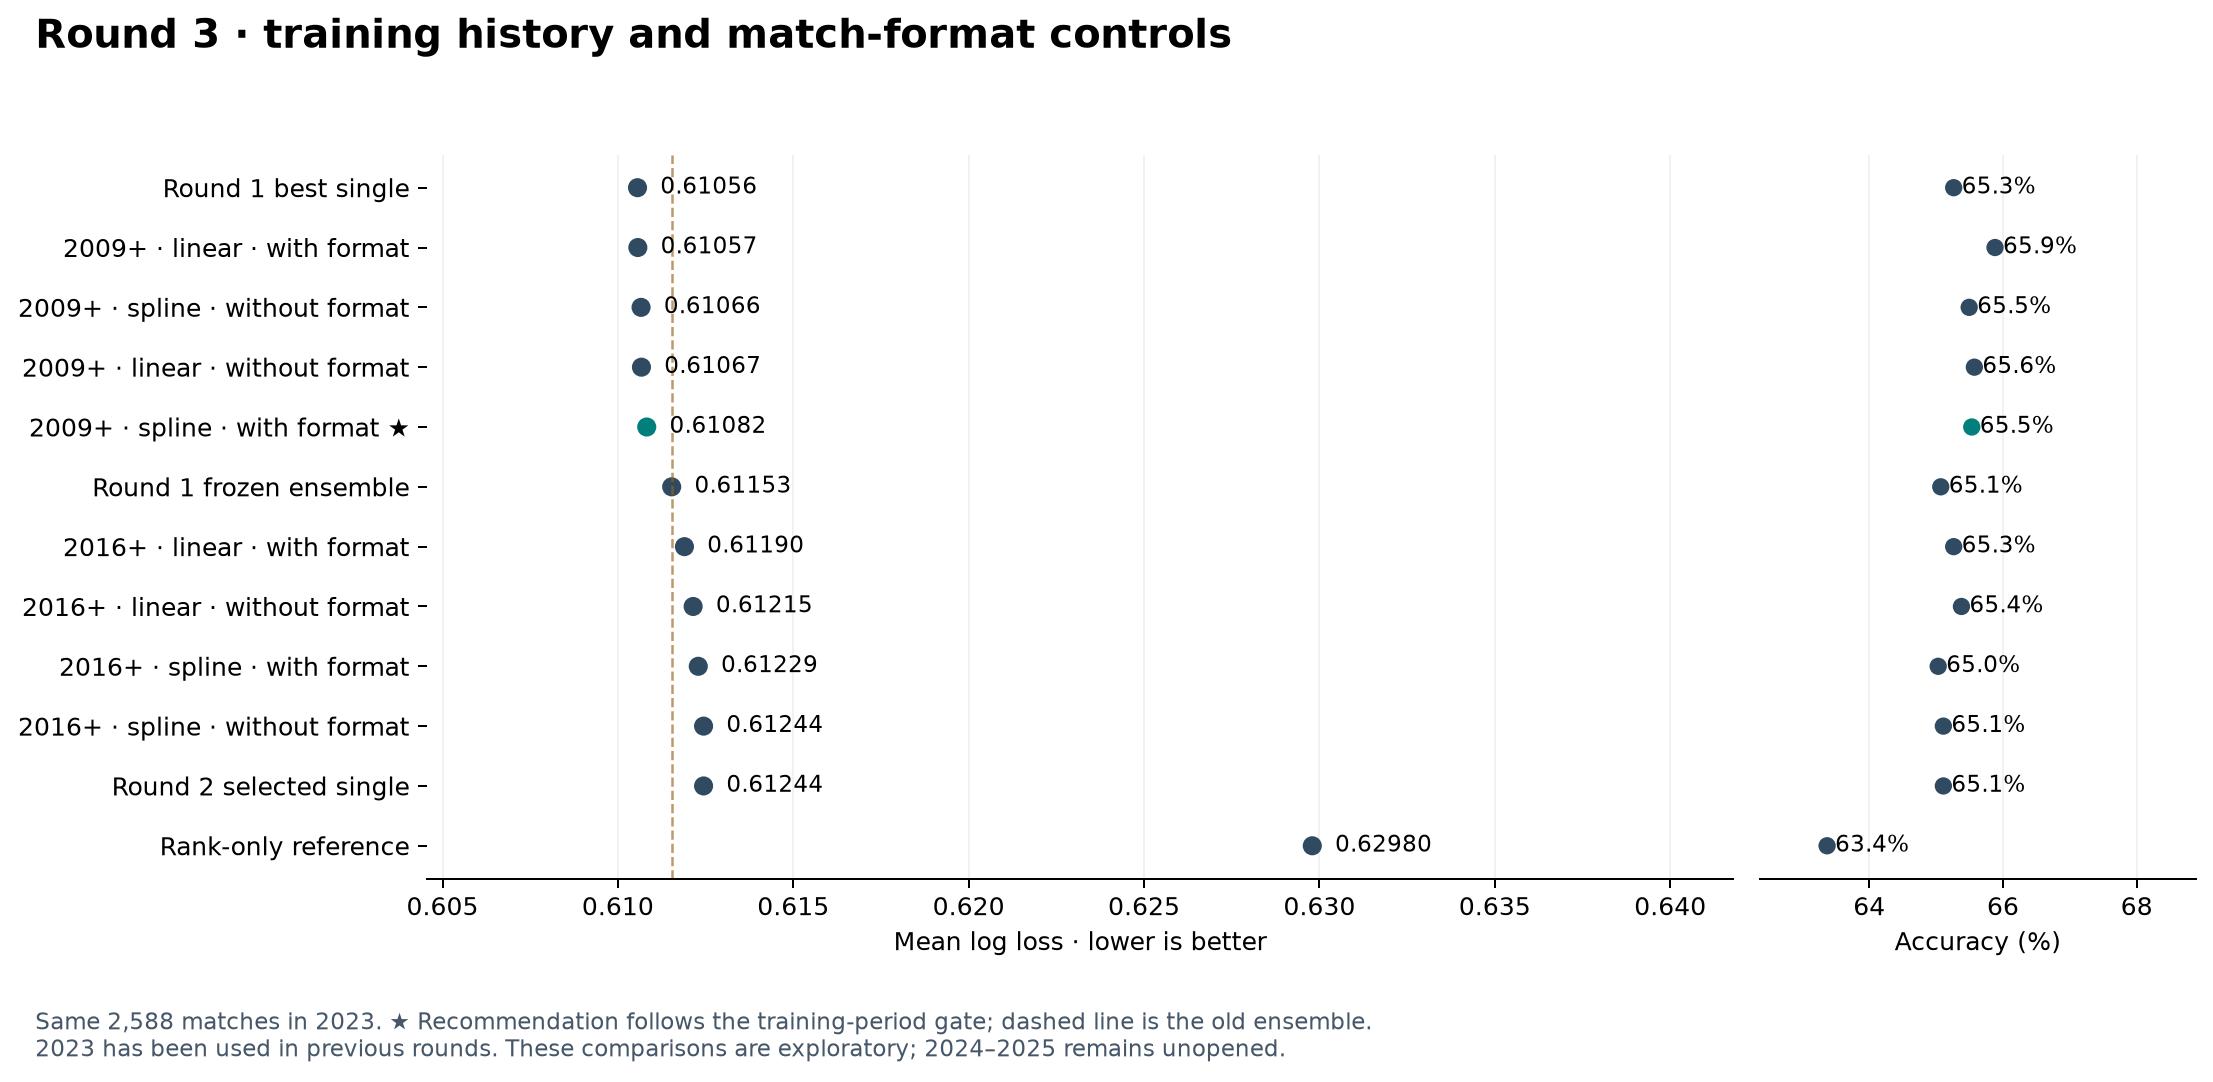

In [2]:
display(comparison_table(data))
display(Image(filename=str(OUT/'round3_comparison.png')))

## 八个家族与分别重调参数的对照

正改善表示对应改动后的 log loss 更低。这些家族各自重新选定正则和近期权重，因此不是完全相同参数的比较。

In [3]:
display(family_table(data))
era,context=contrast_tables(data)
display(era)
display(context)

,training_start,learner,format_context,selected_model,pooled_cv_log_loss,2023_log_loss,2023_accuracy
0,2009,linear,False,history2009_linear_C0.01_half5.0_format0,0.61058,0.61067,0.65572
4,2016,linear,False,history2016_linear_C0.003_half5.0_format0,0.61151,0.61215,0.65379
1,2009,linear,True,history2009_linear_C0.01_half5.0_format1,0.60840,0.61057,0.65881
5,2016,linear,True,history2016_linear_C0.003_half5.0_format1,0.60940,0.61190,0.65263
2,2009,spline,False,history2009_odd_spline_C0.01_context1_half3.0_...,0.60962,0.61066,0.65495
6,2016,spline,False,history2016_odd_spline_C0.003_context1_half3.0...,0.61045,0.61244,0.65108
3,2009,spline,True,history2009_odd_spline_C0.01_context1_half3.0_...,0.60767,0.61082,0.65533
7,2016,spline,True,history2016_odd_spline_C0.003_context1_half3.0...,0.60850,0.61229,0.65031


,learner,format_context,2009_model,2016_model,cv_reduction_with_older_data,2023_reduction_with_older_data
0,linear,False,history2009_linear_C0.01_half5.0_format0,history2016_linear_C0.003_half5.0_format0,0.00093,0.00147
1,linear,True,history2009_linear_C0.01_half5.0_format1,history2016_linear_C0.003_half5.0_format1,0.00100,0.00133
2,spline,False,history2009_odd_spline_C0.01_context1_half3.0_...,history2016_odd_spline_C0.003_context1_half3.0...,0.00083,0.00178
3,spline,True,history2009_odd_spline_C0.01_context1_half3.0_...,history2016_odd_spline_C0.003_context1_half3.0...,0.00083,0.00147


,training_start,learner,with_format_model,without_format_model,cv_reduction_with_format,2023_reduction_with_format
0,2009,linear,history2009_linear_C0.01_half5.0_format1,history2009_linear_C0.01_half5.0_format0,0.00219,0.00010
1,2009,spline,history2009_odd_spline_C0.01_context1_half3.0_...,history2009_odd_spline_C0.01_context1_half3.0_...,0.00196,-0.00016
2,2016,linear,history2016_linear_C0.003_half5.0_format1,history2016_linear_C0.003_half5.0_format0,0.00211,0.00025
3,2016,spline,history2016_odd_spline_C0.003_context1_half3.0...,history2016_odd_spline_C0.003_context1_half3.0...,0.00195,0.00015


## 相同参数下的控制比较

以下每对配置除了训练起点或赛制特征开关外，模型种类、正则和近期权重相同。展示训练期逐年结果，避免仅凭 2023 判断机制。

In [4]:
display(exact_cv_controls(data))
display(data['cv'].sort_values('mean_log_loss'))

,change,reference,candidate,pooled_cv_loss_reduction,reduction_2020,reduction_2021,reduction_2022
0,add_2009_2015_training,history2016_linear_C0.003_halfNone_format0,history2009_linear_C0.003_halfNone_format0,0.00048,-0.00227,0.00197,0.00039
1,add_2009_2015_training,history2016_linear_C0.003_half5.0_format0,history2009_linear_C0.003_half5.0_format0,0.00083,-0.00159,0.00235,0.00056
2,add_2009_2015_training,history2016_linear_C0.01_halfNone_format0,history2009_linear_C0.01_halfNone_format0,0.00143,-0.00143,0.00350,0.00085
3,add_2009_2015_training,history2016_linear_C0.01_half5.0_format0,history2009_linear_C0.01_half5.0_format0,0.00158,-0.00122,0.00400,0.00063
4,add_2009_2015_training,history2016_odd_spline_C0.003_context1_halfNon...,history2009_odd_spline_C0.003_context1_halfNon...,-0.00013,-0.00287,0.00058,0.00051
5,add_2009_2015_training,history2016_odd_spline_C0.01_context1_halfNone...,history2009_odd_spline_C0.01_context1_halfNone...,0.00078,-0.00227,0.00202,0.00108
6,add_2009_2015_training,history2016_odd_spline_C0.003_context1_half3.0...,history2009_odd_spline_C0.003_context1_half3.0...,0.00045,-0.00127,0.00111,0.00067
7,add_2009_2015_training,history2016_odd_spline_C0.01_context1_half3.0_...,history2009_odd_spline_C0.01_context1_half3.0_...,0.00097,-0.00124,0.00203,0.00103
8,add_2009_2015_training,history2016_linear_C0.003_halfNone_format1,history2009_linear_C0.003_halfNone_format1,0.00044,-0.00277,0.00183,0.00066
9,add_2009_2015_training,history2016_linear_C0.003_half5.0_format1,history2009_linear_C0.003_half5.0_format1,0.00081,-0.00192,0.00225,0.00077


,name,family,train_start,mean_log_loss,2020,train_n_2020,2021,train_n_2021,2022,train_n_2022
23,history2009_odd_spline_C0.01_context1_half3.0_...,history2009_spline_format1,2009,0.60767,0.61276,27703,0.61323,28917,0.59996,31305
22,history2009_odd_spline_C0.003_context1_half3.0...,history2009_spline_format1,2009,0.60806,0.61236,27703,0.61322,28917,0.60113,31305
19,history2009_linear_C0.01_half5.0_format1,history2009_linear_format1,2009,0.60840,0.61334,27703,0.61395,28917,0.60078,31305
30,history2016_odd_spline_C0.003_context1_half3.0...,history2016_spline_format1,2016,0.60850,0.61075,10056,0.61431,11270,0.60192,13658
21,history2009_odd_spline_C0.01_context1_halfNone...,history2009_spline_format1,2009,0.60850,0.61485,27703,0.61482,28917,0.59948,31305
17,history2009_linear_C0.003_half5.0_format1,history2009_linear_format1,2009,0.60858,0.61322,27703,0.61380,28917,0.60143,31305
31,history2016_odd_spline_C0.01_context1_half3.0_...,history2016_spline_format1,2016,0.60867,0.61119,10056,0.61542,11270,0.60109,13658
28,history2016_odd_spline_C0.003_context1_halfNon...,history2016_spline_format1,2016,0.60875,0.61150,10056,0.61550,11270,0.60104,13658
20,history2009_odd_spline_C0.003_context1_halfNon...,history2009_spline_format1,2009,0.60894,0.61502,27703,0.61495,28917,0.60033,31305
18,history2009_linear_C0.01_halfNone_format1,history2009_linear_format1,2009,0.60907,0.61401,27703,0.61545,28917,0.60067,31305


## 日期分块的条件不确定性

参考是第一轮冻结集成。这些区间没有修正多轮自适应设计与模型搜索。

In [5]:
display(pd.DataFrame([{'model':n,'loss_reduction':v['mean_log_loss_reduction'],'lower95':v['ci95'][0],'upper95':v['ci95'][1]} for n,v in data['summary']['comparisons_vs_round1'].items()]).sort_values('loss_reduction',ascending=False))
assert data['summary']['final_test_evaluated'] is False
print('2024–2025 final test remains unopened.')

,model,loss_reduction,lower95,upper95
9,round1_best_single,0.00097,-0.00113,0.00303
1,history2009_linear_C0.01_half5.0_format1,0.00096,-0.00163,0.00365
2,history2009_odd_spline_C0.01_context1_half3.0_...,0.00087,-0.00185,0.00318
0,history2009_linear_C0.01_half5.0_format0,0.00086,-0.00204,0.00361
3,history2009_odd_spline_C0.01_context1_half3.0_...,0.00071,-0.00171,0.00300
8,round1_ensemble,0.00000,0.00000,0.00000
5,history2016_linear_C0.003_half5.0_format1,-0.00036,-0.00300,0.00206
4,history2016_linear_C0.003_half5.0_format0,-0.00061,-0.00281,0.00145
7,history2016_odd_spline_C0.003_context1_half3.0...,-0.00076,-0.00314,0.00153
6,history2016_odd_spline_C0.003_context1_half3.0...,-0.00091,-0.00300,0.00102


2024–2025 final test remains unopened.
